# Robust depth estimation from degraded RGB images: fine-tuning Depth Anything V2

Second notebook of the project. The first one compared two losses on a U-Net with a ResNet-34 encoder; plain **L1 won**. Here the same data, pre-processing and Kaggle-matched validation are used to fine-tune a pretrained monocular depth model, **Depth-Anything-V2-Small** (about 25M parameters, a DINOv2 ViT-S encoder with a DPT decoder), with that L1 loss.

**Why the prediction is min-max normalised.** Depth Anything outputs relative inverse depth on an arbitrary scale. The score only looks at each depth map after per-image min-max rescaling, so the model's output is min-max normalised per image before the L1 loss and before evaluation. The loss then ignores scale and offset, exactly like the metric.

The pretrained model is first scored **zero-shot** (no training) to show how much fine-tuning adds.

Kaggle settings: GPU T4, Internet on.

In [1]:
import os, glob, time, random, hashlib, shutil
import numpy as np, pandas as pd, cv2, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from transformers import DepthAnythingForDepthEstimation
from torch.utils.data import Dataset, DataLoader

ROOT = "/kaggle/input/competitions/depth-estimation/competition-data/competition-data"
OUT = "/kaggle/working"
FIG_DIR = f"{OUT}/images"
PRED_DIR = f"{OUT}/predictions"
os.makedirs(FIG_DIR, exist_ok=True)

MODEL_ID = "depth-anything/Depth-Anything-V2-Small-hf"
INPUT_SIZE = 350                       # must be a multiple of the ViT patch size (14)
SEED, EPOCHS, BATCH, WORKERS = 42, 12, 16, 2
LR_ENCODER, LR_DECODER = 1e-5, 1e-4    # gentle on the pretrained encoder, faster on the decoder
DEVICE = "cuda"

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
torch.backends.cudnn.benchmark = True
print("torch", torch.__version__, "| transformers", transformers.__version__, "| GPU", torch.cuda.get_device_name(0))

torch 2.11.0+cu130 | transformers 5.20.2 | GPU Tesla T4


## 1. Load the data into memory (same as notebook 1)

In [2]:
def read_split(split, with_depth):
    files = sorted(os.listdir(f"{ROOT}/{split}/images"))
    imgs = np.stack([cv2.cvtColor(cv2.imread(f"{ROOT}/{split}/images/{f}", cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
                     for f in files])
    deps = (np.stack([cv2.imread(f"{ROOT}/{split}/depths/{f}", cv2.IMREAD_UNCHANGED) for f in files])
            if with_depth else None)
    return files, imgs, deps

t0 = time.time()
train_files, train_imgs, train_deps = read_split("training", True)
val_files, val_imgs, val_deps = read_split("validation", True)
test_files, test_imgs, _ = read_split("testing", False)
print(f"loaded in {time.time() - t0:.0f} s")
print("train", train_imgs.shape, train_deps.shape, "| val", val_imgs.shape, val_deps.shape, "| test", test_imgs.shape)
print("RGB mean brightness (0-255): train %.1f, val %.1f, test %.1f"
      % (train_imgs.mean(), val_imgs.mean(), test_imgs.mean()))

loaded in 109 s
train (6686, 256, 256, 3) (6686, 256, 256) | val (836, 256, 256, 3) (836, 256, 256) | test (836, 256, 256, 3)
RGB mean brightness (0-255): train 9.4, val 9.4, test 9.4


## 2. Overlap between training and validation (same as notebook 1)

In [3]:
h = lambda a: hashlib.md5(a.tobytes()).hexdigest()
train_hashes = {h(d) for d in train_deps}
val_seen = np.array([h(d) in train_hashes for d in val_deps])
unseen_idx = np.where(~val_seen)[0]
print(f"unique training depth maps: {len(train_hashes)} of {len(train_deps)}")
print(f"validation images whose depth map is also in training: {val_seen.sum()} of {len(val_deps)}; unseen: {len(unseen_idx)}")

unique training depth maps: 5868 of 6686
validation images whose depth map is also in training: 240 of 836; unseen: 596


## 3. Pre-processing, targets and the Kaggle metric (same as notebook 1)

Per-image contrast stretch (99th percentile) and ImageNet normalisation for the input, per-image min-max depth as the target, and validation with the same steps as `imgs2csv.py`.

In [4]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

def preprocess(img_u8):
    x = img_u8.astype(np.float32)
    x = np.clip(x / max(np.percentile(x, 99), 1.0), 0, 1)   # per-image contrast stretch for low light
    return (x - MEAN) / STD

def normalise_depth(d):
    d = d.astype(np.float32)
    return (d - d.min()) / (d.max() - d.min() + 1e-6)

def submission_pixels(img_u8):
    # same steps as the course's imgs2csv.py
    image = cv2.resize(img_u8, (128, 128))
    image = image / 255.
    image = (image - np.min(image)) / (np.max(image) - np.min(image) + 1e-6)
    return np.uint8(image * 255.)

def pred_to_png(p):
    return np.uint8(np.round(np.clip(p, 0, 1) * 255))

VAL_GT = np.stack([submission_pixels(d) for d in val_deps]).astype(np.float64)

def kaggle_rmse(preds, idx=None):
    P = np.stack([submission_pixels(pred_to_png(p)) for p in preds]).astype(np.float64)
    G = VAL_GT
    if idx is not None:
        P, G = P[idx], G[idx]
    return float(np.sqrt(np.mean((P - G) ** 2)))

class DepthDataset(Dataset):
    def __init__(self, imgs, deps=None, augment=False):
        self.imgs, self.deps, self.augment = imgs, deps, augment
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        x = preprocess(self.imgs[i])
        y = normalise_depth(self.deps[i]) if self.deps is not None else np.zeros(x.shape[:2], np.float32)
        if self.augment and random.random() < 0.5:          # horizontal flip keeps depth valid
            x, y = x[:, ::-1], y[:, ::-1]
        x = torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))
        y = torch.from_numpy(np.ascontiguousarray(y))[None]
        return x, y

train_dl = DataLoader(DepthDataset(train_imgs, train_deps, augment=True), batch_size=BATCH, shuffle=True,
                      num_workers=WORKERS, pin_memory=True, drop_last=True,
                      generator=torch.Generator().manual_seed(SEED))
val_dl = DataLoader(DepthDataset(val_imgs, val_deps), batch_size=32, num_workers=WORKERS)
test_dl = DataLoader(DepthDataset(test_imgs), batch_size=32, num_workers=WORKERS)
print(len(train_dl), "training batches per epoch")

417 training batches per epoch


## 4. Model and training loop

- Images are resized from 256 to 350 px on the GPU (350 is a multiple of the 14-px patch size), and the predicted map is resized back to 256.
- The prediction is min-max normalised per image, then compared with the target using L1.
- AdamW with two learning rates (encoder 1e-5, decoder 1e-4), one-cycle schedule with 10% warm-up, mixed precision, gradient clipping at 1.0, 12 epochs, batch 16, horizontal-flip augmentation.

In [5]:
def load_model():
    return DepthAnythingForDepthEstimation.from_pretrained(MODEL_ID).to(DEVICE)

def minmax(d):
    mn = d.amin(dim=(2, 3), keepdim=True)
    mx = d.amax(dim=(2, 3), keepdim=True)
    return (d - mn) / (mx - mn + 1e-6)

def forward_depth(model, x):
    h, w = x.shape[-2:]
    xi = F.interpolate(x, size=(INPUT_SIZE, INPUT_SIZE), mode="bilinear", align_corners=False)
    d = model(pixel_values=xi).predicted_depth.unsqueeze(1)
    d = F.interpolate(d, size=(h, w), mode="bilinear", align_corners=False)
    return minmax(d.float())

@torch.no_grad()
def predict(model, loader, tta=False):
    model.eval()
    out = []
    for x, _ in loader:
        x = x.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            p = forward_depth(model, x)
            if tta:
                p = (p + forward_depth(model, x.flip(-1)).flip(-1)) / 2
        out.append(p.float().squeeze(1).cpu().numpy())
    return np.concatenate(out)

model = load_model()
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

24.8M parameters


## 5. Zero-shot score (pretrained model, no training)

In [6]:
zero_shot = {tta: predict(model, val_dl, tta=tta) for tta in (False, True)}
for tta, p in zero_shot.items():
    print(f"zero-shot, TTA {tta}: val RMSE {kaggle_rmse(p):.3f} | unseen {kaggle_rmse(p, unseen_idx):.3f}")

zero-shot, TTA False: val RMSE 33.864 | unseen 34.981
zero-shot, TTA True: val RMSE 33.859 | unseen 34.999


## 6. Fine-tune

In [7]:
def train():
    seed_everything(SEED)
    model = load_model()
    groups = [
        {"params": [p for n, p in model.named_parameters() if n.startswith("backbone")], "lr": LR_ENCODER},
        {"params": [p for n, p in model.named_parameters() if not n.startswith("backbone")], "lr": LR_DECODER},
    ]
    opt = torch.optim.AdamW(groups, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LR_ENCODER, LR_DECODER],
                                                total_steps=EPOCHS * len(train_dl), pct_start=0.1)
    scaler = torch.amp.GradScaler()
    history, best = [], float("inf")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        t0, loss_sum, n = time.time(), 0.0, 0
        for x, y in train_dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16):
                p = forward_depth(model, x)
            loss = F.l1_loss(p.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            loss_sum += loss.item() * len(x); n += len(x)
        rmse = kaggle_rmse(predict(model, val_dl))
        history.append(dict(epoch=epoch, train_l1=loss_sum / n, val_rmse=rmse, seconds=time.time() - t0))
        flag = ""
        if rmse < best:
            best, flag = rmse, "  <- best"
            torch.save(model.state_dict(), f"{OUT}/depth_anything_ft.pt")
        print(f"epoch {epoch:2d} | train L1 {loss_sum / n:.4f} | val RMSE {rmse:.3f} | {time.time() - t0:.0f} s{flag}")
    return pd.DataFrame(history)

history = train()

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

epoch  1 | train L1 0.0657 | val RMSE 24.346 | 144 s  <- best
epoch  2 | train L1 0.0534 | val RMSE 19.119 | 144 s  <- best
epoch  3 | train L1 0.0470 | val RMSE 17.876 | 142 s  <- best
epoch  4 | train L1 0.0432 | val RMSE 17.628 | 143 s  <- best
epoch  5 | train L1 0.0396 | val RMSE 16.393 | 143 s  <- best
epoch  6 | train L1 0.0370 | val RMSE 16.228 | 144 s  <- best
epoch  7 | train L1 0.0344 | val RMSE 15.542 | 143 s  <- best
epoch  8 | train L1 0.0321 | val RMSE 15.145 | 143 s  <- best
epoch  9 | train L1 0.0302 | val RMSE 14.802 | 143 s  <- best
epoch 10 | train L1 0.0287 | val RMSE 14.520 | 143 s  <- best
epoch 11 | train L1 0.0275 | val RMSE 14.424 | 143 s  <- best
epoch 12 | train L1 0.0270 | val RMSE 14.417 | 144 s  <- best


## 7. Results on validation

In [8]:
model.load_state_dict(torch.load(f"{OUT}/depth_anything_ft.pt", map_location=DEVICE))
best_epoch = int(history.loc[history.val_rmse.idxmin(), "epoch"])
ft = {tta: predict(model, val_dl, tta=tta) for tta in (False, True)}
rows = []
for name, preds in (("zero-shot", zero_shot), ("fine-tuned", ft)):
    for tta, p in preds.items():
        rows.append(dict(model=name, tta=tta, rmse_all=kaggle_rmse(p), rmse_unseen=kaggle_rmse(p, unseen_idx)))
results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))
print(f"\nbest epoch {best_epoch}, mean seconds per epoch {history.seconds.mean():.0f}")

use_tta = bool(kaggle_rmse(ft[True]) < kaggle_rmse(ft[False]))
p = ft[use_tta]
print(f"submission uses TTA: {use_tta}, validation RMSE {kaggle_rmse(p):.3f}")

bright = val_imgs.mean(axis=(1, 2, 3))
cuts = np.quantile(bright, [1 / 3, 2 / 3])
groups = {"darkest third": bright <= cuts[0],
          "middle third": (bright > cuts[0]) & (bright <= cuts[1]),
          "brightest third": bright > cuts[1]}
for g, mask in groups.items():
    idx = np.where(mask)[0]
    print(f"{g:16s} brightness {bright[idx].min():5.1f}-{bright[idx].max():5.1f} | n={len(idx)} | RMSE {kaggle_rmse(p, idx):.3f}")

     model   tta  rmse_all  rmse_unseen
 zero-shot False    33.864       34.981
 zero-shot  True    33.859       34.999
fine-tuned False    14.417       15.565
fine-tuned  True    14.409       15.603

best epoch 12, mean seconds per epoch 143
submission uses TTA: True, validation RMSE 14.409
darkest third    brightness   3.4-  8.1 | n=279 | RMSE 17.983
middle third     brightness   8.1- 10.9 | n=278 | RMSE 14.085
brightest third  brightness  10.9- 21.9 | n=279 | RMSE 10.052


## 8. Figures

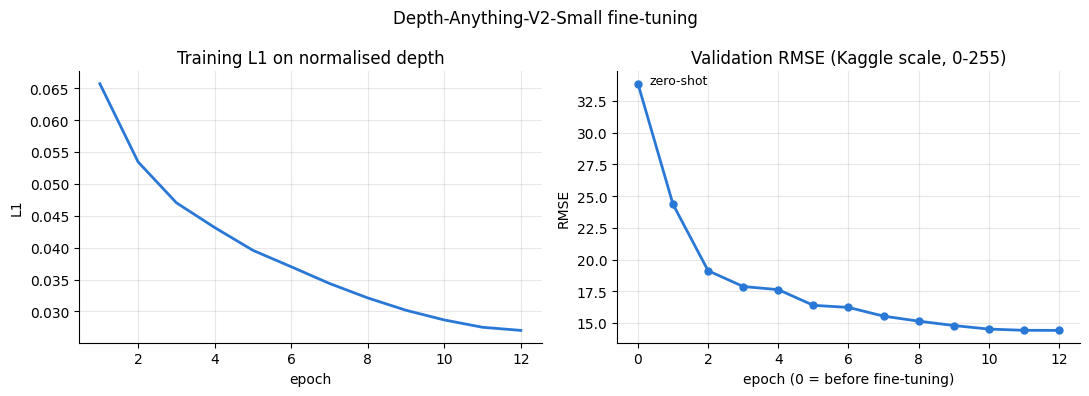

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.epoch, history.train_l1, color="#2a78d6", lw=2)
axes[1].plot([0] + history.epoch.tolist(), [kaggle_rmse(zero_shot[False])] + history.val_rmse.tolist(),
             color="#2a78d6", lw=2, marker="o", ms=5)
axes[1].annotate("zero-shot", (0, kaggle_rmse(zero_shot[False])), textcoords="offset points", xytext=(8, 0), fontsize=9)
axes[0].set(title="Training L1 on normalised depth", xlabel="epoch", ylabel="L1")
axes[1].set(title="Validation RMSE (Kaggle scale, 0-255)", xlabel="epoch (0 = before fine-tuning)", ylabel="RMSE")
for a in axes:
    a.grid(alpha=0.3); a.spines[["top", "right"]].set_visible(False)
plt.suptitle("Depth-Anything-V2-Small fine-tuning")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/depth_anything_training_curves.png", dpi=150); plt.show()

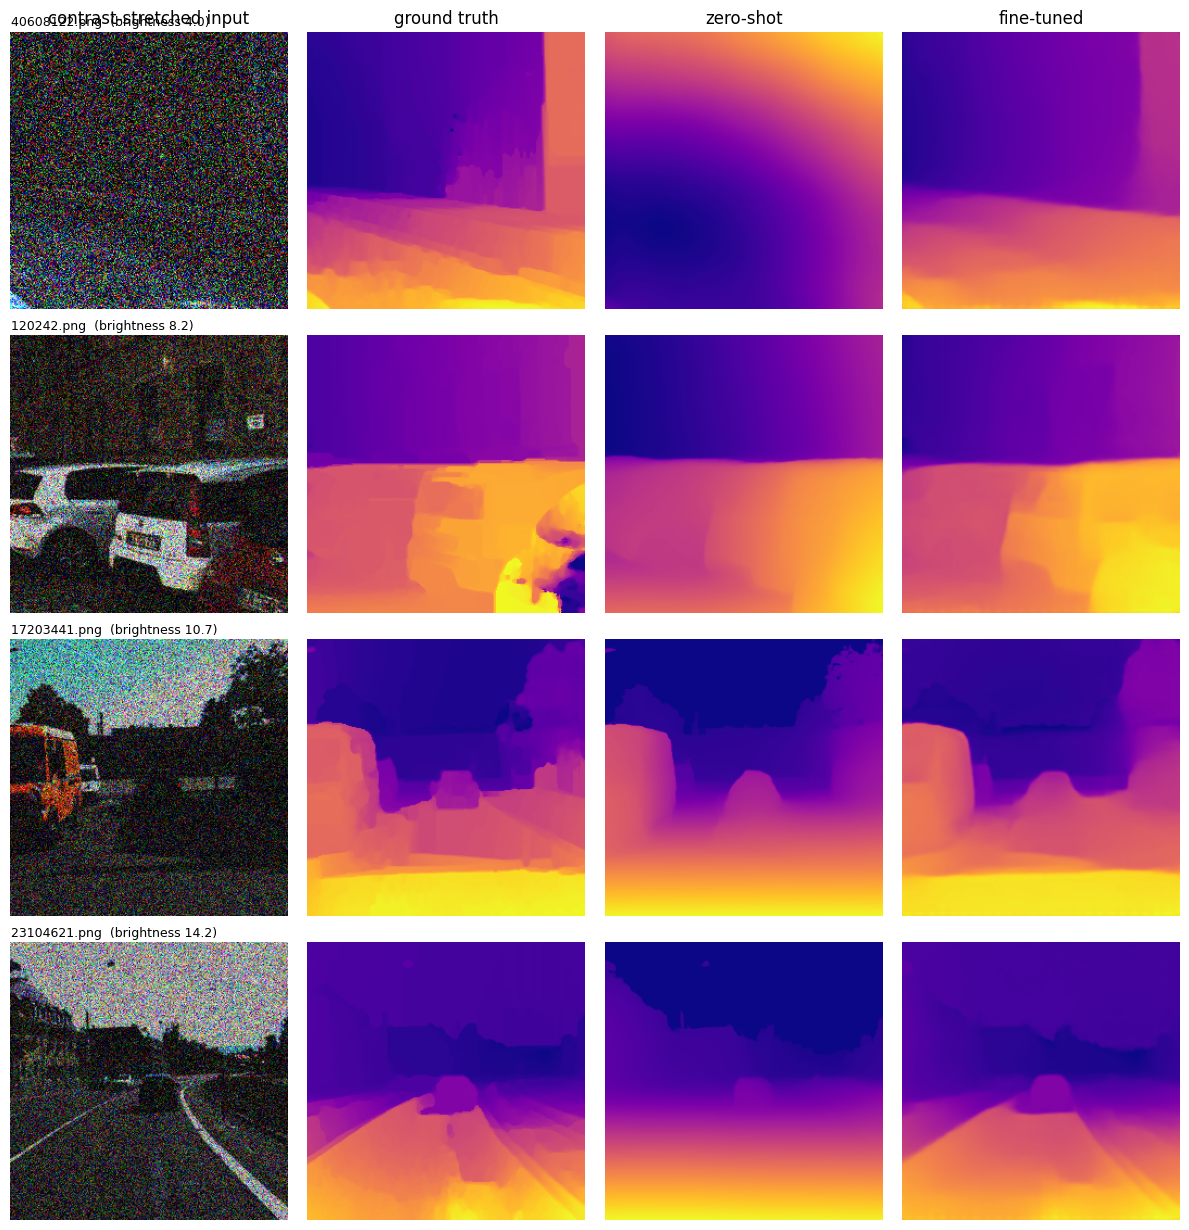

In [10]:
# the same four unseen validation images as notebook 1
order = unseen_idx[np.argsort(bright[unseen_idx])]
picks = [order[int(q * (len(order) - 1))] for q in (0.05, 0.35, 0.65, 0.95)]
cols = ["contrast-stretched input", "ground truth", "zero-shot", "fine-tuned"]
fig, ax = plt.subplots(len(picks), 4, figsize=(12, 3.1 * len(picks)))
for r, i in enumerate(picks):
    stretched = np.clip(val_imgs[i] / max(np.percentile(val_imgs[i], 99), 1.0), 0, 1)
    panels = [stretched, normalise_depth(val_deps[i]), zero_shot[False][i], ft[False][i]]
    for c, im in enumerate(panels):
        ax[r, c].imshow(im, cmap=None if c == 0 else "plasma")
        ax[r, c].axis("off")
        if r == 0:
            ax[r, c].set_title(cols[c])
    ax[r, 0].text(0, -6, f"{val_files[i]}  (brightness {bright[i]:.1f})", fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/depth_anything_samples.png", dpi=120); plt.show()

## 9. Test predictions and submission (same steps as notebook 1)

In [11]:
test_pred = predict(model, test_dl, tta=use_tta)
os.makedirs(PRED_DIR, exist_ok=True)
for f, p in zip(test_files, test_pred):
    cv2.imwrite(f"{PRED_DIR}/{f}", pred_to_png(p))
print(len(os.listdir(PRED_DIR)), "prediction PNGs written")

# provided by the course (imgs2csv.py), unchanged apart from being called with our paths
def images_to_csv_with_metadata(image_folder, output_csv):
    data = []
    for idx, filename in enumerate(sorted(os.listdir(image_folder))):
        if filename.endswith(".png"):
            filepath = os.path.join(image_folder, filename)
            image = cv2.imread(filepath, cv2.IMREAD_UNCHANGED)
            image = cv2.resize(image, (128, 128))
            image = image / 255.
            image = (image - np.min(image)) / (np.max(image) - np.min(image) + 1e-6)
            image = np.uint8(image * 255.)
            image_flat = image.flatten()
            row = [idx, filename] + image_flat.tolist()
            data.append(row)
    num_columns = len(data[0]) - 2 if data else 0
    column_names = ["id", "ImageID"] + [indx for indx in range(num_columns)]
    df = pd.DataFrame(data, columns=column_names)
    df.to_csv(output_csv, index=False)

images_to_csv_with_metadata(PRED_DIR, f"{OUT}/submission.csv")
sub = pd.read_csv(f"{OUT}/submission.csv")
sample = pd.read_csv("/kaggle/input/competitions/depth-estimation/predictions.csv", usecols=["id", "ImageID"])
print("submission shape:", sub.shape, "| sample shape:", (len(sample), sub.shape[1]))
print("same ImageIDs in the same order as the sample:", sub.ImageID.tolist() == sample.ImageID.tolist())

836 prediction PNGs written
submission shape: (836, 16386) | sample shape: (836, 16386)
same ImageIDs in the same order as the sample: True


In [12]:
# keep /kaggle/working tidy: submission.csv and images/ stay; checkpoints and PNG predictions go
for f in glob.glob(f"{OUT}/*.pt"):
    os.remove(f)
shutil.rmtree(PRED_DIR)
print(sorted(os.listdir(OUT)))

['__notebook__.ipynb', 'images', 'submission.csv']
